# Summary Plot

Load precomputed layerwise summaries and plot the main regression/RSA/RDM figures without recomputing analyses.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd

PROJECT_ROOT = Path.cwd().resolve()
while not (PROJECT_ROOT / 'ismir2026' / 'natural_sound_align').exists() and PROJECT_ROOT != PROJECT_ROOT.parent:
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from ismir2026.natural_sound_align.cache_summary import COMPILED_ROOT, load_compiled_summaries, load_cached_rsa_payload, select_plot_summary
from ismir2026.natural_sound_align.rsa import plot_model_vs_human_rdm

dataset = 'NH2015'  # 'NH2015', 'N2015', or 'B2021'
layer_mode = 'best'  # 'final' or 'best'

regression_all, rsa_all = load_compiled_summaries(compiled_root=COMPILED_ROOT)

def resolve_dataset(requested, regression_table, rsa_table):
    reg_sets = set(regression_table['dataset_name'].unique())
    rsa_sets = set(rsa_table['dataset_name'].unique())
    available = sorted(reg_sets & rsa_sets)
    if not available:
        raise ValueError('No overlapping datasets between regression and RSA tables.')
    if requested not in available:
        print(f"Requested dataset '{requested}' not found. Using '{available[0]}' instead.")
        return available[0]
    return requested

dataset = resolve_dataset(dataset, regression_all, rsa_all)

regression_summary = select_plot_summary(
    regression_all,
    dataset_name=dataset,
    layer_mode=layer_mode,
    metric_column='cv_subject_mean',
)
rsa_summary = select_plot_summary(
    rsa_all,
    dataset_name=dataset,
    layer_mode=layer_mode,
    metric_column='median_spearman',
)

foundation_regression = regression_summary.query("model_name != 'SPECTEMP'").reset_index(drop=True)
spectemp_regression = regression_summary.query("model_name == 'SPECTEMP'").reset_index(drop=True)
foundation_rsa = rsa_summary.query("model_name != 'SPECTEMP'").reset_index(drop=True)
spectemp_rsa = rsa_summary.query("model_name == 'SPECTEMP'").reset_index(drop=True)

layer_mode_label = 'Best layer' if layer_mode == 'best' else 'Final layer'

display(regression_summary)
display(rsa_summary)


,model_name,representation_name,n_voxels,n_splits,source_dim,median_noise_corrected_r2,mean_noise_corrected_r2,median_noise_corrected_r2_raw,mean_noise_corrected_r2_raw,median_r2,...,cv_subject_mean,cv_subject_median,cv_subject_sem,cv_subject_std,value_column,dataset_name,layer_index,layer_depth,is_final,result_dir
0,MULAN,layer_09,7694,10,1024,0.765762,0.721824,0.765762,0.770365,0.346425,...,0.761989,0.758771,0.014229,0.040247,median_r2_test_c,NH2015,9.0,9,False,/home/hjkim/selective_auditory/ismir2026/natur...
1,JUKEBOX,layer_37,7694,10,4800,0.760240,0.721496,0.760240,0.803984,0.334701,...,0.757826,0.751861,0.016274,0.046029,median_r2_test_c,NH2015,37.0,37,False,/home/hjkim/selective_auditory/ismir2026/natur...
2,MERT,layer_05,7694,10,1024,0.749149,0.718122,0.749149,0.794878,0.343446,...,0.753849,0.747028,0.022300,0.063074,median_r2_test_c,NH2015,5.0,5,False,/home/hjkim/selective_auditory/ismir2026/natur...
3,CLAP,layer_03,7694,10,768,0.751750,0.721248,0.751750,0.776488,0.341161,...,0.750429,0.745370,0.016307,0.046123,median_r2_test_c,NH2015,3.0,3,False,/home/hjkim/selective_auditory/ismir2026/natur...
4,MERT95,layer_05,7694,10,768,0.735700,0.710898,0.735700,0.764776,0.346186,...,0.740025,0.731421,0.021279,0.060186,median_r2_test_c,NH2015,5.0,5,False,/home/hjkim/selective_auditory/ismir2026/natur...
5,CLAP_MUSIC_SPEECH,layer_03,7694,10,1024,0.732772,0.699986,0.732772,0.748630,0.318240,...,0.728712,0.729563,0.023148,0.065474,median_r2_test_c,NH2015,3.0,3,False,/home/hjkim/selective_auditory/ismir2026/natur...
6,MUSICGEN_SMALL,layer_10,7694,10,1024,0.658713,0.658327,0.658713,0.734803,0.303598,...,0.661185,0.662964,0.016581,0.046899,median_r2_test_c,NH2015,10.0,10,False,/home/hjkim/selective_auditory/ismir2026/natur...
7,WAV2VEC2,layer_03,7694,10,768,0.656898,0.650834,0.656898,0.707796,0.300646,...,0.660553,0.652561,0.021654,0.061246,median_r2_test_c,NH2015,3.0,3,False,/home/hjkim/selective_auditory/ismir2026/natur...
8,MUSICGEN_LARGE,layer_34,7694,10,2048,0.609617,0.606027,0.609617,0.662714,0.270298,...,0.610923,0.616054,0.020342,0.057535,median_r2_test_c,NH2015,34.0,34,False,/home/hjkim/selective_auditory/ismir2026/natur...
9,MUSICGEN_MELODY_LARGE,layer_46,7694,10,2048,0.602491,0.598647,0.602491,0.658540,0.240379,...,0.604326,0.598324,0.023068,0.065246,median_r2_test_c,NH2015,46.0,46,False,/home/hjkim/selective_auditory/ismir2026/natur...


,model_name,representation_name,n_repetitions,n_participants,n_splits,mean_spearman,median_spearman,participant_sem,mean_leave_one_out_neural_spearman,dataset_name,layer_index,layer_depth,is_final,result_dir
0,MERT,layer_04,8,8,10,0.504783,0.510128,0.009904,0.754764,NH2015,4.0,4,False,/home/hjkim/selective_auditory/ismir2026/natur...
1,MERT95,layer_05,8,8,10,0.497703,0.497986,0.006947,0.754764,NH2015,5.0,5,False,/home/hjkim/selective_auditory/ismir2026/natur...
2,JUKEBOX,layer_29,8,8,10,0.492072,0.486500,0.007249,0.754764,NH2015,29.0,29,False,/home/hjkim/selective_auditory/ismir2026/natur...
3,MULAN,layer_06,8,8,10,0.476230,0.480516,0.007083,0.754764,NH2015,6.0,6,False,/home/hjkim/selective_auditory/ismir2026/natur...
4,CLAP_MUSIC_SPEECH,layer_03,8,8,10,0.425292,0.431201,0.006857,0.754764,NH2015,3.0,3,False,/home/hjkim/selective_auditory/ismir2026/natur...
5,CLAP,layer_02,8,8,10,0.421643,0.420338,0.005212,0.754764,NH2015,2.0,2,False,/home/hjkim/selective_auditory/ismir2026/natur...
6,SPECTEMP,avgpool,8,8,10,0.412462,0.410600,0.011872,0.754764,NH2015,NaN,0,False,/home/hjkim/selective_auditory/ismir2026/natur...
7,WAV2VEC2,layer_02,8,8,10,0.378551,0.383810,0.009462,0.754764,NH2015,2.0,2,False,/home/hjkim/selective_auditory/ismir2026/natur...
8,MUSICGEN_SMALL,layer_14,8,8,10,0.370816,0.363087,0.014120,0.754764,NH2015,14.0,14,False,/home/hjkim/selective_auditory/ismir2026/natur...
9,MUSICGEN_LARGE,layer_34,8,8,10,0.350769,0.342905,0.008705,0.754764,NH2015,34.0,34,False,/home/hjkim/selective_auditory/ismir2026/natur...


## Regression & RSA Summary

,dataset_name,model_name,representation_name,cv_subject_mean,cv_subject_median,median_noise_corrected_r2
0,NH2015,MULAN,layer_09,0.761989,0.758771,0.765762
1,NH2015,JUKEBOX,layer_37,0.757826,0.751861,0.760240
2,NH2015,MERT,layer_05,0.753849,0.747028,0.749149
3,NH2015,CLAP,layer_03,0.750429,0.745370,0.751750
4,NH2015,MERT95,layer_05,0.740025,0.731421,0.735700
5,NH2015,CLAP_MUSIC_SPEECH,layer_03,0.728712,0.729563,0.732772
6,NH2015,MUSICGEN_SMALL,layer_10,0.661185,0.662964,0.658713
7,NH2015,WAV2VEC2,layer_03,0.660553,0.652561,0.656898
8,NH2015,MUSICGEN_LARGE,layer_34,0.610923,0.616054,0.609617
9,NH2015,MUSICGEN_MELODY_LARGE,layer_46,0.604326,0.598324,0.602491


,dataset_name,model_name,representation_name,mean_spearman,median_spearman,n_participants
0,NH2015,MERT,layer_04,0.504783,0.510128,8
1,NH2015,MERT95,layer_05,0.497703,0.497986,8
2,NH2015,JUKEBOX,layer_29,0.492072,0.486500,8
3,NH2015,MULAN,layer_06,0.476230,0.480516,8
4,NH2015,CLAP_MUSIC_SPEECH,layer_03,0.425292,0.431201,8
5,NH2015,CLAP,layer_02,0.421643,0.420338,8
6,NH2015,SPECTEMP,avgpool,0.412462,0.410600,8
7,NH2015,WAV2VEC2,layer_02,0.378551,0.383810,8
8,NH2015,MUSICGEN_SMALL,layer_14,0.370816,0.363087,8
9,NH2015,MUSICGEN_LARGE,layer_34,0.350769,0.342905,8


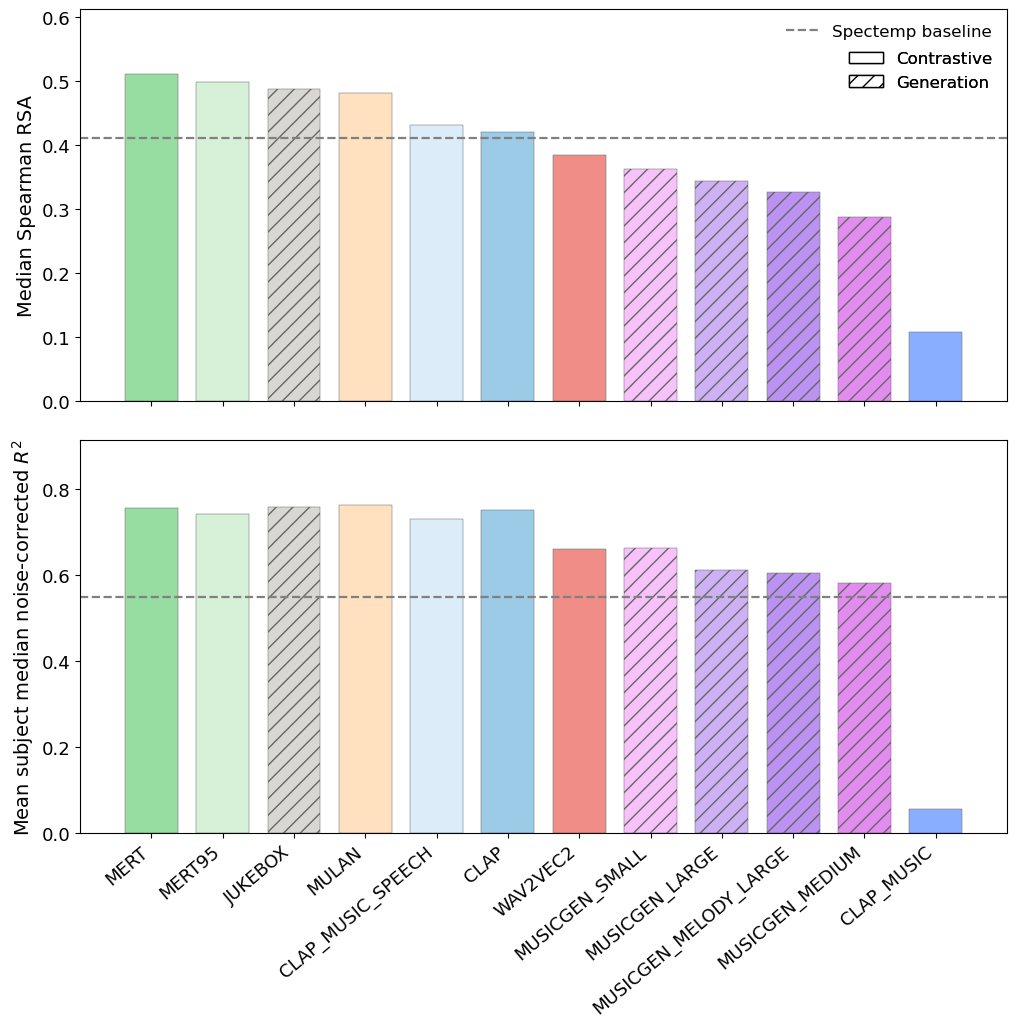

In [5]:
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

display(regression_summary[['dataset_name', 'model_name', 'representation_name', 'cv_subject_mean', 'cv_subject_median', 'median_noise_corrected_r2']])
display(rsa_summary[['dataset_name', 'model_name', 'representation_name', 'mean_spearman', 'median_spearman', 'n_participants']])

default_model_order = [
    'CLAP',
    'CLAP_MUSIC',
    'CLAP_MUSIC_SPEECH',
    'MULAN',
    'MERT',
    'MERT95',
    'WAV2VEC2',
    'JUKEBOX',
    'MUSICGEN_SMALL',
    'MUSICGEN_MEDIUM',
    'MUSICGEN_LARGE',
    'MUSICGEN_MELODY_LARGE',
]

# Keep current hues but shift to softer pastel tones.
model_color_map = {
    'CLAP': '#9ccbe8',
    'CLAP_MUSIC': "#89aeff",
    'CLAP_MUSIC_SPEECH': '#dcedf9',
    'MULAN': '#ffe1bf',
    'MERT': '#97dca0',
    'MERT95': '#d7f1d8',
    'WAV2VEC2': '#ef8d86',
    'JUKEBOX': "#d9d7d4",
    'MUSICGEN_SMALL': '#f7c2fa',
    'MUSICGEN_MEDIUM': '#e38cf0',
    'MUSICGEN_LARGE': '#ceb1f4',
    'MUSICGEN_MELODY_LARGE': '#bb91f2',
}

available_models = sorted(
    set(foundation_regression['model_name'].unique()) | set(foundation_rsa['model_name'].unique()),
    key=lambda name: (default_model_order.index(name) if name in default_model_order else len(default_model_order), name),
)

reg_plot = (
    foundation_regression.set_index('model_name')
    .reindex(available_models)
    .reset_index()
    .rename(columns={'index': 'model_name'})
)
rsa_plot = (
    foundation_rsa.set_index('model_name')
    .reindex(available_models)
    .reset_index()
    .rename(columns={'index': 'model_name'})
)

# Shared-x requires one common order; sort by RSA score descending.
order_df = rsa_plot[['model_name', 'median_spearman']].copy()
order_df['median_spearman'] = order_df['median_spearman'].fillna(float('-inf'))
ordered_models = order_df.sort_values('median_spearman', ascending=False)['model_name'].tolist()

reg_plot = reg_plot.set_index('model_name').reindex(ordered_models).reset_index()
rsa_plot = rsa_plot.set_index('model_name').reindex(ordered_models).reset_index()

x = list(range(len(ordered_models)))
bar_colors = [model_color_map.get(model_name, '#d0d0d0') for model_name in ordered_models]

def model_texture_group(model_name):
    return 'generation' if (model_name.startswith('MUSICGEN') or model_name == 'JUKEBOX') else 'contrastive'

texture_hatch = {
    'contrastive': '',
    'generation': '//',
}
texture_label = {
    'contrastive': 'Contrastive',
    'generation': 'Generation',
}
bar_hatches = [texture_hatch[model_texture_group(model_name)] for model_name in ordered_models]

fig_width = max(8.2, 0.68 * len(ordered_models) + 2.2)
fig_height = fig_width
fig, axes = plt.subplots(2, 1, figsize=(fig_width, fig_height), sharex=True)

baseline_rsa = float(spectemp_rsa['median_spearman'].iloc[0]) if len(spectemp_rsa) else None
bars_rsa = axes[0].bar(x, rsa_plot['median_spearman'], color=bar_colors, width=0.74, edgecolor='#666666', linewidth=0.35)
for bar, hatch in zip(bars_rsa, bar_hatches):
    bar.set_hatch(hatch)
if baseline_rsa is not None:
    axes[0].axhline(
        baseline_rsa,
        linestyle='--',
        color='gray',
        linewidth=1.6,
    )
axes[0].set_ylabel('Median Spearman RSA', fontsize=14)
axes[0].set_ylim(0, 0.51*1.2)   ## max value * 1.2
axes[0].set_xlim(-1, len(ordered_models))
axes[0].tick_params(axis='y', labelsize=13)
axes[0].margins(x=0.01)

baseline_subject_mean = float(spectemp_regression['cv_subject_mean'].iloc[0]) if len(spectemp_regression) else None
bars_reg = axes[1].bar(x, reg_plot['cv_subject_mean'], color=bar_colors, width=0.74, edgecolor='#666666', linewidth=0.35)
for bar, hatch in zip(bars_reg, bar_hatches):
    bar.set_hatch(hatch)
if baseline_subject_mean is not None:
    axes[1].axhline(
        baseline_subject_mean,
        linestyle='--',
        color='gray',
        linewidth=1.6,
    )
axes[1].set_ylabel('Mean subject median noise-corrected $R^2$', fontsize=14)
axes[1].set_ylim(0, 0.76*1.2)
axes[1].set_xlim(-1, len(ordered_models))
axes[1].tick_params(axis='y', labelsize=13)
axes[1].margins(x=0.01)

baseline_handles = [
    Line2D([0], [0], color='gray', linestyle='--', linewidth=1.6, label='Spectemp baseline')
]
texture_handles = [
    Patch(facecolor='white', edgecolor='black', hatch=texture_hatch['contrastive'], label=texture_label['contrastive']),
    Patch(facecolor='white', edgecolor='black', hatch=texture_hatch['generation'], label=texture_label['generation']),
]

baseline_legend = axes[0].legend(handles=baseline_handles, frameon=False, fontsize=12, loc='upper right')
axes[0].add_artist(baseline_legend)
axes[0].add_artist(axes[0].legend(handles=texture_handles, frameon=False, fontsize=12, loc='upper right', bbox_to_anchor=(1.0, 0.93)))

axes[1].set_xticks(x)
axes[1].set_xticklabels(ordered_models, rotation=40, ha='right', fontsize=13)

fig.subplots_adjust(left=0.10, right=0.995, bottom=0.20, top=0.995, hspace=0.10)
plt.show()

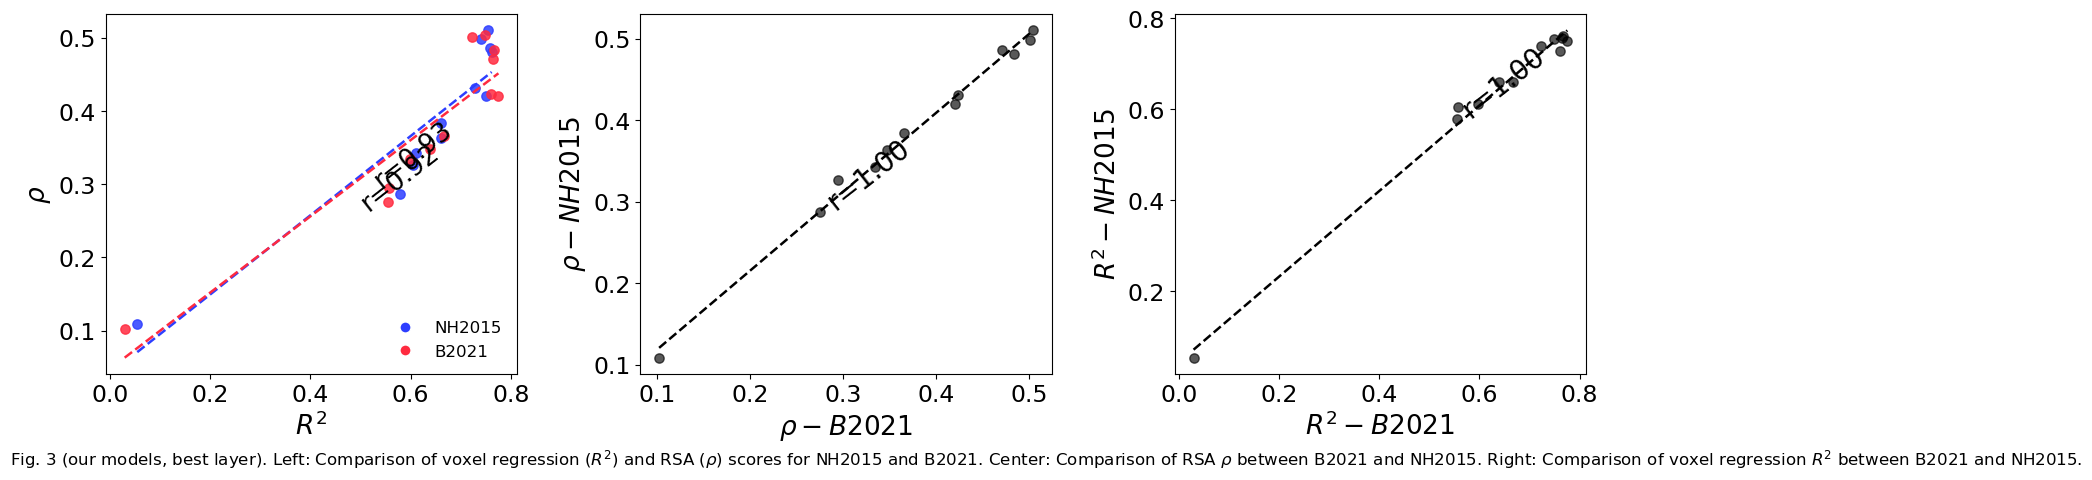

In [ ]:
import numpy as np
from matplotlib.lines import Line2D

target_datasets = ['NH2015', 'B2021']

reg_best = pd.concat(
    [
        select_plot_summary(
            regression_all,
            dataset_name=dataset_name,
            layer_mode='best',
            metric_column='cv_subject_mean',
        )
        for dataset_name in target_datasets
    ],
    ignore_index=True,
    sort=False,
 )
rsa_best = pd.concat(
    [
        select_plot_summary(
            rsa_all,
            dataset_name=dataset_name,
            layer_mode='best',
            metric_column='median_spearman',
        )
        for dataset_name in target_datasets
    ],
    ignore_index=True,
    sort=False,
 )

merged = reg_best[['model_name', 'dataset_name', 'cv_subject_mean']].merge(
    rsa_best[['model_name', 'dataset_name', 'median_spearman']],
    on=['model_name', 'dataset_name'],
    how='inner',
)

# Focus on foundation models only.
merged = merged.query("model_name != 'SPECTEMP'").copy()

pivot_r2 = merged.pivot(index='model_name', columns='dataset_name', values='cv_subject_mean')
pivot_rho = merged.pivot(index='model_name', columns='dataset_name', values='median_spearman')

required_cols = set(target_datasets)
r2_models = set(pivot_r2.dropna(subset=target_datasets).index) if required_cols.issubset(pivot_r2.columns) else set()
rho_models = set(pivot_rho.dropna(subset=target_datasets).index) if required_cols.issubset(pivot_rho.columns) else set()
common_models = sorted(r2_models & rho_models)

if not common_models:
    raise ValueError('NH2015/B2021에 대해 regression+RSA best 점수가 모두 있는 공통 모델이 없습니다.')

left_df = merged[merged['model_name'].isin(common_models)].copy()
rho_pair = pivot_rho.loc[common_models, target_datasets].copy()
r2_pair = pivot_r2.loc[common_models, target_datasets].copy()

dataset_colors = {'NH2015': '#2d3eff', 'B2021': '#ff2a3f'}

def add_fit_with_r(ax, x, y, color='black', linestyle='--', linewidth=1.8):
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    if len(x) >= 2 and np.std(x) > 0 and np.std(y) > 0:
        slope, intercept = np.polyfit(x, y, 1)
        xs = np.linspace(x.min(), x.max(), 100)
        ax.plot(xs, slope * xs + intercept, linestyle=linestyle, color=color, linewidth=linewidth)
        return float(pd.Series(x).corr(pd.Series(y)))
    return np.nan

fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))

# Left: R2 vs rho for both datasets.
for dataset_name in target_datasets:
    subset = left_df.query('dataset_name == @dataset_name').copy()
    x = subset['cv_subject_mean'].to_numpy()
    y = subset['median_spearman'].to_numpy()
    axes[0].scatter(x, y, s=45, alpha=0.85, color=dataset_colors[dataset_name], edgecolor=dataset_colors[dataset_name])
    r_value = add_fit_with_r(axes[0], x, y, color=dataset_colors[dataset_name])
    if np.isfinite(r_value):
        text_x = np.nanpercentile(x, 8)
        text_y = np.nanpercentile(y, 8) + (0.03 if dataset_name == 'NH2015' else 0.01)
        axes[0].text(text_x, text_y, f'r={r_value:.2f}', fontsize=19, rotation=38, color='black')

axes[0].set_xlabel(r'$R^2$', fontsize=19)
axes[0].set_ylabel(r'$\rho$', fontsize=19)
axes[0].tick_params(axis='both', labelsize=17)
axes[0].legend(
    handles=[
        Line2D([0], [0], marker='o', color='w', markerfacecolor=dataset_colors['NH2015'], markersize=8, label='NH2015'),
        Line2D([0], [0], marker='o', color='w', markerfacecolor=dataset_colors['B2021'], markersize=8, label='B2021'),
    ],
    frameon=False,
    fontsize=12,
    loc='lower right',
)

# Center: rho(B2021) vs rho(NH2015).
x_rho = rho_pair['B2021'].to_numpy()
y_rho = rho_pair['NH2015'].to_numpy()
axes[1].scatter(x_rho, y_rho, s=45, alpha=0.65, color='black')
r_center = add_fit_with_r(axes[1], x_rho, y_rho, color='black')
if np.isfinite(r_center):
    axes[1].text(np.nanpercentile(x_rho, 10), np.nanpercentile(y_rho, 10), f'r={r_center:.2f}', fontsize=20, rotation=38)
axes[1].set_xlabel(r'$\rho - B2021$', fontsize=19)
axes[1].set_ylabel(r'$\rho - NH2015$', fontsize=19)
axes[1].tick_params(axis='both', labelsize=17)

# Right: R2(B2021) vs R2(NH2015).
x_r2 = r2_pair['B2021'].to_numpy()
y_r2 = r2_pair['NH2015'].to_numpy()
axes[2].scatter(x_r2, y_r2, s=45, alpha=0.65, color='black')
r_right = add_fit_with_r(axes[2], x_r2, y_r2, color='black')
if np.isfinite(r_right):
    axes[2].text(np.nanpercentile(x_r2, 10), np.nanpercentile(y_r2, 10), f'r={r_right:.2f}', fontsize=20, rotation=38)
axes[2].set_xlabel(r'$R^2 - B2021$', fontsize=19)
axes[2].set_ylabel(r'$R^2 - NH2015$', fontsize=19)
axes[2].tick_params(axis='both', labelsize=17)

# caption = (
#     'Fig. 3 (our models, best layer). Left: Comparison of voxel regression ($R^2$) and RSA ($\\rho$) scores for NH2015 and B2021. '
#     'Center: Comparison of RSA $\\rho$ between B2021 and NH2015. '
#     'Right: Comparison of voxel regression $R^2$ between B2021 and NH2015.'
# )

fig.subplots_adjust(left=0.07, right=0.995, top=0.98, bottom=0.23, wspace=0.30)
# fig.text(0.01, 0.03, caption, ha='left', va='bottom', fontsize=12)
plt.show()

## Human vs Model RDM

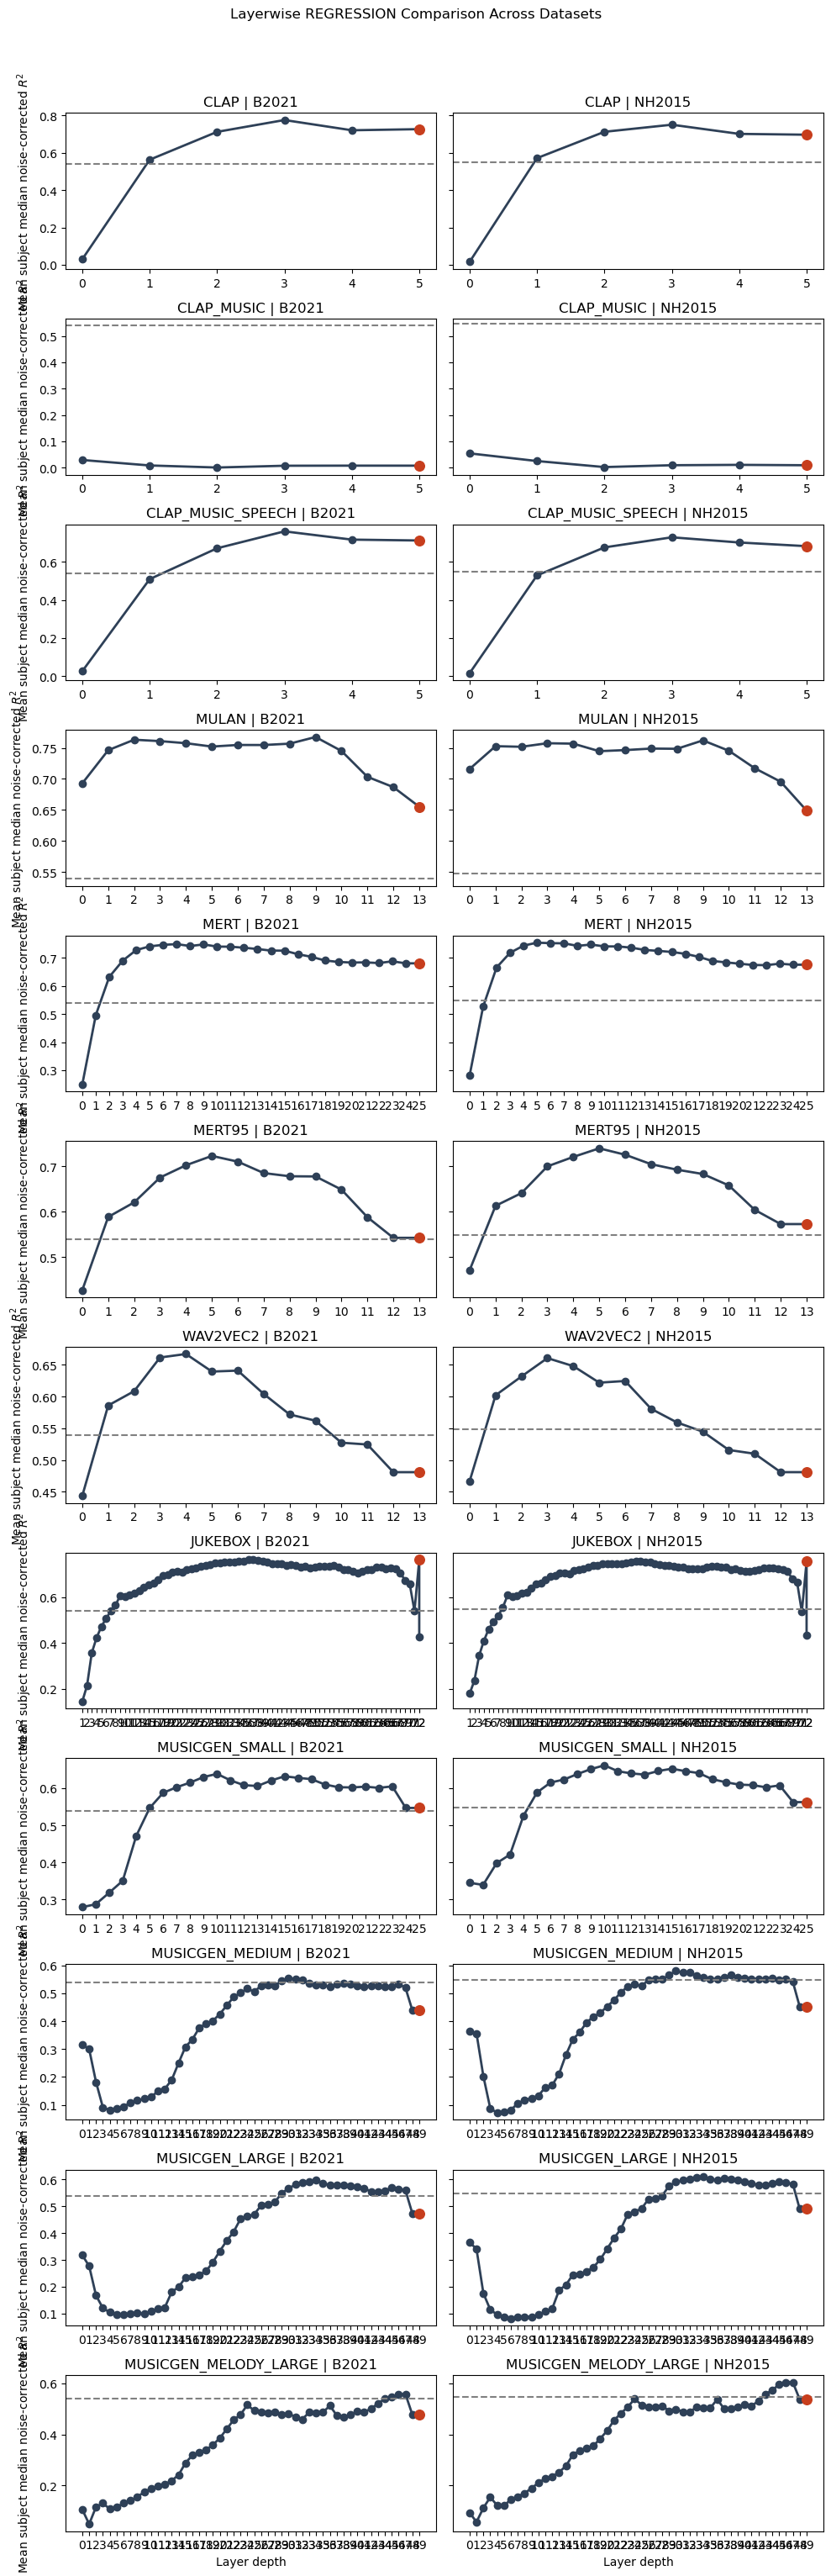

In [3]:
comparison_mode = 'regression'  # 'regression' or 'RSA'

mode_key = comparison_mode.strip().lower()
if mode_key == 'regression':
    layerwise_table = regression_all
    metric_column = 'cv_subject_mean'
    y_label = 'Mean subject median noise-corrected $R^2$'
    line_color = '#2E4057'
elif mode_key == 'rsa':
    layerwise_table = rsa_all
    metric_column = 'median_spearman'
    y_label = 'Median Spearman RSA'
    line_color = '#048A81'
else:
    raise ValueError("comparison_mode must be either 'regression' or 'RSA'.")

default_model_order = ['CLAP', 'CLAP_MUSIC', 'CLAP_MUSIC_SPEECH', 'MULAN', 'MERT', 'MERT95', 'WAV2VEC2', 'JUKEBOX', 'MUSICGEN_SMALL', 'MUSICGEN_MEDIUM', 'MUSICGEN_LARGE', 'MUSICGEN_MELODY_LARGE']
available_models = [model for model in default_model_order if model in layerwise_table['model_name'].unique()]
comparison_models = available_models  # replace with a custom list if you want a subset

if not comparison_models:
    raise ValueError('No models available for comparison in the compiled summaries.')

model_dataset_sets = []
for model_name in comparison_models:
    datasets_for_model = set(layerwise_table.query("model_name == @model_name")['dataset_name'].unique())
    if datasets_for_model:
        model_dataset_sets.append(datasets_for_model)

if model_dataset_sets:
    datasets = sorted(set.intersection(*model_dataset_sets))
else:
    datasets = []

if not datasets:
    datasets = sorted(layerwise_table['dataset_name'].unique())
    print("No common datasets across selected models. Plotting all available datasets instead:", datasets)

fig_height = max(10, 2.5 * len(comparison_models))
fig_width = max(10, 4 * len(datasets))
fig, axes = plt.subplots(nrows=len(comparison_models), ncols=len(datasets), figsize=(fig_width, fig_height), sharex=False, sharey='row', squeeze=False)

for row_index, model_name in enumerate(comparison_models):
    for col_index, dataset_name in enumerate(datasets):
        ax = axes[row_index, col_index]
        layerwise = layerwise_table.query("dataset_name == @dataset_name and model_name == @model_name").sort_values('layer_depth').reset_index(drop=True).copy()
        if layerwise.empty:
            ax.set_axis_off()
            continue
        if (layerwise['layer_depth'] < 0).any():
            nonfinal_depths = layerwise.loc[~layerwise['is_final'], 'layer_depth']
            fallback_depth = int(nonfinal_depths.max()) + 1 if len(nonfinal_depths) else 0
            layerwise.loc[layerwise['is_final'], 'layer_depth'] = fallback_depth

        ax.plot(layerwise['layer_depth'], layerwise[metric_column], marker='o', color=line_color, linewidth=2)
        final_row = layerwise.query('is_final').iloc[0]
        ax.scatter([final_row['layer_depth']], [final_row[metric_column]], color='#C73E1D', s=70, zorder=3)

        baseline_row = layerwise_table.query("dataset_name == @dataset_name and model_name == 'SPECTEMP'")
        if len(baseline_row):
            ax.axhline(float(baseline_row.iloc[0][metric_column]), linestyle='--', color='gray', linewidth=1.5)

        ax.set_title(f'{model_name} | {dataset_name}')
        ax.set_xticks(layerwise['layer_depth'])
        if row_index == len(comparison_models) - 1:
            ax.set_xlabel('Layer depth')
        if col_index == 0:
            ax.set_ylabel(y_label)

fig.suptitle(f'Layerwise {comparison_mode.upper()} Comparison Across Datasets', y=1.02)
fig.tight_layout()
plt.show()
